In [1]:
%load_ext autoreload
%autoreload 2

from analyse_TMS import ProtocoleAnalysis
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from plot_atlas_function import plot_atlas_3d
import sys
from scipy.stats import spearmanr, pearsonr
sys.path.append(str(Path.cwd().parent / "analysis"))

PROJECT_ROOT = Path.cwd().parent


Failed to read module file 'c:\Users\bedba\SimNIBS-4.6\simnibs_env\Lib\pydoc_data\topics.py' for module 'pydoc_data.topics': UnicodeDecodeError
Traceback (most recent call last):
  File "c:\Users\bedba\SimNIBS-4.6\simnibs_env\Lib\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bedba\SimNIBS-4.6\simnibs_env\Lib\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bedba\SimNIBS-4.6\simnibs_env\Lib\importlib\__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1140, in

In [2]:
# General histogramme plot for ranking.
def histogram_metric(
    protocole,
    metric,
    n=20,
    percentile=95,
    threshold_pct=50,
    ref_metric=None,
    by_volume=True,
    ascending=False,
    color="steelblue",
    xlabel="Region (atlas label)",
    ylabel="",
    title=None,
    show_global=False,
    global_value=None,
    global_label="",
    figsize=(10,8),
    show_atlas_3d=False,      
    show_no_atlas=False,
    show_values=False
):
    top = protocole.rank_regions(
        n=n,
        metric=metric,
        percentile=percentile,
        threshold_pct=threshold_pct,
        by_volume=by_volume,
        ascending=ascending,
        reference_metric=ref_metric,
    )

    region_ids = [r[0] for r in top]
    values = [r[1] for r in top]
    labels = protocole.get_labels_for_regions(region_ids)
    metric_label = f"P{percentile}" if metric == "percentile" else metric
    if ref_metric is not None:
        metric_label = f"P{percentile}" if ref_metric == "percentile" else ref_metric

    if isinstance(n, str) or n >= 50:
        labels = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(labels, values, color=color)
    if show_values:
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    
    if show_global:
        global_value = protocole.global_reference(metric=metric, percentile=percentile, ref_metric=ref_metric, threshold_pct=threshold_pct) if global_value is None else global_value
        global_label = f"Global {metric_label} ({global_value:.4f})"
        ax.axhline(
            global_value,
            color="firebrick",
            linestyle="--",
            linewidth=1.5,
            label=global_label,
        )
        ax.legend()

    if not (isinstance(n, str) or n >= 50):
        ax.set_xticks(labels)
        ax.set_xticklabels(labels, rotation=45, ha="right")

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    n_label = "All" if n == "all" else n
    title_sup = f"Volume Above {threshold_pct}% of global " if metric == "above_threshold" else ""
    title_sup = f"Volume below {threshold_pct}% of global " if metric == "below_threshold" else title_sup
    title_sup = "Stimulation ratio in " if metric == "stimulation_ratio" else title_sup
    ax.set_title(title) if title is not None else ax.set_title(f"Top {n_label} Regions — {title_sup}{metric_label} | {study_id}")

    plt.tight_layout()

    if show_atlas_3d:
        plot_atlas_3d(protocole, top, metric=metric, percentile=percentile,
                      show_no_atlas=show_no_atlas)

    return fig, ax

In [4]:
# Générale scatter plot for metrics comparisons.
def scatter_metrics(
    metric_x,
    metric_y,
    xlabel,
    ylabel,
    labels=None,
    annotate=False,
    identity=True,
    figsize=(10, 6),
):
    """
    Compare deux métriques régionales dans un scatter plot.

    metric_x, metric_y : dict, Dictionnaires {region_id: valeur}.
    x_label, y_label   : string, name of the axes label.
    labels             : dict, optional {region_id: nom} pour annoter les points.
    annotate           : bool, optional Affiche le nom de chaque région.
    identity           : bool, optional Affiche la droite identité.
    figsize            : tuple, optional determine la taille de la figure.
    """

    regions = sorted(set(metric_x) & set(metric_y))

    x = np.array([metric_x[r] for r in regions])
    y = np.array([metric_y[r] for r in regions])

    spear_rho, spear_p = spearmanr(x, y)

    pear_rho, pear_p = pearsonr(x, y)

    fig, ax = plt.subplots(figsize=figsize)

    ax.scatter(x, y)

    if annotate and labels is not None:
        for r, xi, yi in zip(regions, x, y):
            ax.text(xi, yi, labels[r], fontsize=7)


    lim_min = [0, 1.1 * min(x.max(), y.max())]
    if identity is True:
        ax.plot(lim_min, lim_min, "--", color="gray", alpha=0.6, label='Identity')

    stats = (
        f"Spearman ρ = {spear_rho:.3f}\n"
        f"Pearson r = {pear_rho:.3f}"
    )

    ax.text(
        0.02, 0.98,
        stats,
        transform=ax.transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.8)
    )

    lim_x = [0, 1.1 * x.max()]
    lim_y = [0, 1.1 * y.max()]

    ax.set_xlim(lim_x)
    ax.set_ylim(lim_y)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    ax.grid(alpha=0.3)

    ax.legend()

    ax.set_title(f"{xlabel} vs {ylabel}")

    plt.tight_layout()

    return fig, ax

In [3]:
# ─── Study id ─────────────────
study_id = "addicott2024"#"trojak2015"#"bellini2024"#"prikryl2014"#
p = ProtocoleAnalysis(study_id=study_id, head_model="ernie")


# ── Print number of tetrahedra per region ─────────────────────────────────────
stats = p.region_stats()
sorted_by_elements = sorted(stats.items(), key=lambda x: x[1]["n_elements"], reverse=False)#[-n:]
print(f"{'Region':<6} {'N Elements':>12} {'Volume (mm³)':>15}")
print("-" * 40)
total = 0
volume_tot = 0
for r, s in sorted_by_elements:
    total += s['n_elements']
    volume_tot += s['volume_mm3']
    print(f"{r:<6} {s['n_elements']:>12} {s['volume_mm3']:>15.2f}")
print(f"The total number of tetrahedron in the WM and GM is :{total}")
print(f"The total volume of WM and GM is :{volume_tot:.2f}")
print(f"nomber of region:{len(stats.keys())}")
print(f"list of region : {stats.keys()}")

Region   N Elements    Volume (mm³)
----------------------------------------
18              309         1851.86
7               403         1778.13
74              413         1047.64
67              428          613.14
68              560          204.41
66              614          685.15
11              662          586.90
75              664          314.61
21              737          525.63
73             1209         1477.03
20             1273         2252.14
72             1307         1009.27
71             1525         1843.45
55             1670          982.50
69             1831          914.41
16             1842         3122.91
5              2037         3003.31
118            2161         1540.76
187            2177         1875.99
127            2467         1870.11
6              2473         5267.69
194            2674          641.57
10             2724         2065.10
128            2740         1711.29
190            2762         1397.37
174            2843    

In [33]:
print(p.global_reference(metric="mean"))
print(p.global_reference(metric="percentile", percentile=95), 1743364*0.05)
print(p.global_reference(metric="percentile", percentile=99), 1743364*0.01)
print(p.global_reference(metric="percentile", percentile=99.9), 1743364*0.001)
print(p.global_reference(metric="percentile", percentile=99.99), 1743364*0.0001)
print(p.global_reference(metric="percentile", percentile=99.999), 1743364*0.00001)
print(p.global_reference(metric="percentile", percentile=99.9999), 1743364*0.000001)

8.393552679878072
26.01950604743319 87168.20000000001
48.402284490944744 17433.64
86.83958256266921 1743.364
123.36746693060624 174.3364
142.6158050912077 17.43364
150.19245673928407 1.743364


In [ ]:
# ── Histogram of top N regions by volume ──────────────────────────────────────
n     = 20


sorted_by_volume = sorted(stats.items(), key=lambda x: x[1]["volume_mm3"], reverse=True)[:n]
labels = [str(r[0]) for r in sorted_by_volume]
values = [r[1]["volume_mm3"] for r in sorted_by_volume]

n_label = "All" if n == "all" else n
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, values, color="steelblue")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45)
ax.set_xlabel("Region (atlas label)")
ax.set_ylabel("Volume (mm³)")
ax.set_title(f"Top {n_label} Regions by Volume | {study_id}")
plt.tight_layout()
plt.show()

In [ ]:
# Scatter plots for metric comparison

# scatter plot for mean-median
fig, ax = scatter_metrics(
    p.mean_by_region(),
    p.median_by_region(),
    "Weighted mean",
    "Weighted median",
)

# scatter plot for mean-p95
fig, ax = scatter_metrics(
    p.mean_by_region(),
    p.weighted_percentile_by_region(95),
    "Weighted mean",
    "P95",
    identity=True
)

# scatter plot for median-p95
fig, ax = scatter_metrics(
    p.median_by_region(),
    p.weighted_percentile_by_region(95),
    "Weighted median",
    "P95",annotate=True,
    identity=True
)

# scatter plot for mean-fraction above 100% mean
fig, ax = scatter_metrics(
    p.mean_by_region(),
    p.fraction_above_threshold(100, ref_metric="mean"),
    "Weighted mean",
    "volume above 100% of globale mean"
)

# scatter plot for mean-fraction above 75% P95
fig, ax = scatter_metrics(
    p.weighted_percentile_by_region(95),
    p.fraction_above_threshold(75, ref_metric="percentile"),
    "P95",
    "volume above 75% of globale P95"
)

In [ ]:
# box/violin plot of the tetraedron distribution per region
rep = p.plot_region_distribution( kind="violin", n_regions=15, percentile=99, figsize=(14, 10),ascending=False, max_points_per_region=20000)

In [ ]:
# ──— Volume-weighted median by region ────────────────────────────────
fig, ax = histogram_metric(
            protocole=p,
            metric="median",
            n=15,
            color="steelblue",
            ylabel="Volume-weighted median E-field [V/m]",
            show_global=True,
            show_atlas_3d=True,
            show_values=True
        )

In [ ]:
# ──— Volume-weighted mean by region ────────────────────────────────
n = 15

fig, ax = histogram_metric(
            protocole=p,
            metric="mean",
            n=n,
            color="steelblue",
            ylabel="Volume-weighted mean E-field [V/m]",
            show_global=True,
            show_atlas_3d=False,
            show_values=True
        )

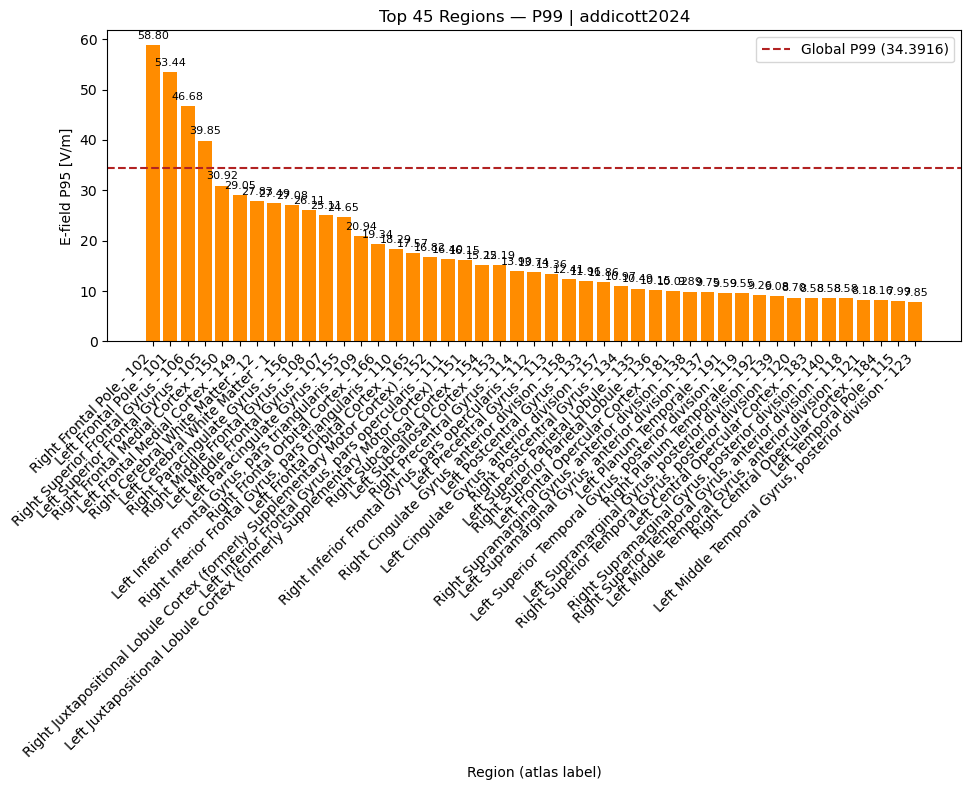

In [5]:
# ──— P95 by region ────────────────────────────────────────────
fig, ax = histogram_metric(
            protocole=p,
            metric="percentile",
            percentile=99,
            n=45,
            color="darkorange",
            ylabel="E-field P95 [V/m]",
            show_global=True,
            show_atlas_3d=True,
            show_values=True
        )

In [ ]:
#  — Stimulation ratio  (regional metric over global metric) ─────────────────────────────
ref_metric = "percentile"
fig, ax = histogram_metric(
            protocole=p,
            metric="stimulation_ratio",
            ref_metric=ref_metric,
            percentile=95,
            n=15,
            ascending=False,
            color="red",
            ylabel=f"Stimulation ratio ({ref_metric} / global {ref_metric})",
            show_atlas_3d=False,
            show_values=True
        )

In [ ]:
# ──— Focality (P95/Mean ratio) ────────────────────────────────────────────
percentile = 95
fig, ax = histogram_metric(
            protocole=p,
            metric="focality",
            percentile=percentile,
            n=45,
            color="mediumpurple",
            ylabel=f"Focality (P{percentile} / Mean)",
            show_global=True,
        )

In [ ]:
#  — Focality (volume ratio above globale P(percentile)) ─────────────────────────────
fig, ax = histogram_metric(
            protocole=p,
            metric="above_threshold",
            percentile=95,
            threshold_pct=75,
            ref_metric="percentile",
            n=15,
            color="seagreen",
            ylabel="Volume above threshold (%)",
            show_global=True,
            show_values=True
        )

In [ ]:
#  — Focality (volume ratio above globale mean) ─────────────────────────────
fig, ax = histogram_metric(
            protocole=p,
            metric="above_threshold",
            threshold_pct=300,
            ref_metric="mean",
            n=30,
            color="seagreen",
            ylabel="Volume above threshold (%)",
            show_global=True,
        )

In [ ]:
#  — reverse Focality (volume ratio below 30% of globale mean) ─────────────────────────────
fig, ax = histogram_metric(
            protocole=p,
            metric="below_threshold",
            percentile=95,
            threshold_pct=50,
            ref_metric="mean",
            n=30,
            color="seagreen",
            ylabel="Volume below threshold (%)",
        )

In [ ]:
# histogramme of p90-p95-p99
all_p90 = dict(p.rank_regions(n="all", metric="percentile", percentile=90))
all_p95 = dict(p.rank_regions(n="all", metric="percentile", percentile=95))
all_p99 = dict(p.rank_regions(n="all", metric="percentile", percentile=99))

# ordre défini par P99 décroissant — top 10
ordered_ids = sorted(all_p90, key=lambda r: all_p90[r], reverse=True)[:49]

# labels anatomiques
labels = p.get_labels_for_regions(ordered_ids)

x     = np.arange(len(ordered_ids))
width = 0.25

p90s = [all_p90.get(r, 0) for r in ordered_ids]
p95s = [all_p95.get(r, 0) for r in ordered_ids]
p99s = [all_p99.get(r, 0) for r in ordered_ids]

fig, ax = plt.subplots(figsize=(14, 12))
ax.bar(x - width, p90s, width, label="P90", color="steelblue")
ax.bar(x,         p95s, width, label="P95", color="darkorange")
ax.bar(x + width, p99s, width, label="P99", color="firebrick")
if len(x) <= 50:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_xlabel("Region")
ax.set_ylabel("E-field (V/m per A/µs)")
ax.set_title(f"P90 vs P95 vs P99 sorted by P99 | {study_id}")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# — Mean vs P95 sorted by Mean ───────────────────────────────────
percentile = 95
all_mean = dict(p.rank_regions(n="all", metric="mean"))
all_p95  = dict(p.rank_regions(n="all", metric="percentile", percentile=percentile))

# ordre défini par la moyenne décroissante — top 10
ordered_labels = sorted(all_mean, key=lambda r: all_mean[r], reverse=True)[:20]

# labels anatomiques
labels = p.get_labels_for_regions(ordered_labels)

x     = np.arange(len(ordered_labels))
width = 0.35

means = [all_mean.get(r, 0) for r in ordered_labels]
p95s  = [all_p95.get(r, 0)  for r in ordered_labels]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - width/2, means, width, label="Mean", color="steelblue")
ax.bar(x + width/2, p95s,  width, label=f"P{percentile}",  color="darkorange")
if len(ordered_labels) <=50:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_xlabel("Region (atlas label)")
ax.set_ylabel("E-field (V/m per A/µs)")
ax.set_title(f"Mean vs P{percentile} sorted by Mean | {study_id}")
ax.legend()
plt.tight_layout()
plt.show()